# Government and Non-Government Funding Analysis in LIS

This notebook examines the distribution and temporal trends of government and non-government funding in Library and Information Science (LIS) publications from 2014 to 2024.

Each publication is classified into one of four mutually exclusive funding configurations:

1. Government-only
2. Non-government-only
3. Government/Non-government
4. No funders

The analysis includes overall distributions, annual counts and proportions, temporal visualizations, and linear regression trend estimates.

In [1]:
# Install the packages required for statistical analysis and visualization.
%pip install -q \
    pandas \
    numpy \
    matplotlib \
    statsmodels \
    openpyxl

Note: you may need to restart the kernel to use updated packages.


You should consider upgrading via the 'c:\users\jkimi\appdata\local\programs\python\python37\python.exe -m pip install --upgrade pip' command.


## 1. Import Libraries

In [1]:
import ast
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.api as sm

## 2. Analysis Configuration

In [2]:
# =============================================================================
# Input file
# =============================================================================

LIS_FILE = Path(
    "./LIS_data_cleaned_with_OND_Class.csv"
)

# =============================================================================
# Column settings
# =============================================================================

YEAR_COLUMN = "Year"
FUNDING_CLASS_COLUMN = "Funding_Details_OND_Class"

# =============================================================================
# Analysis period
# =============================================================================

START_YEAR = 2014
END_YEAR = 2024

# =============================================================================
# Output directories
# =============================================================================

OUTPUT_DIR = Path(
    "./LIS_gov_non_gov_funding_analysis"
)
    
TABLE_DIR = OUTPUT_DIR / "tables"
FIGURE_DIR = OUTPUT_DIR / "figures"

TABLE_DIR.mkdir(
    parents=True,
    exist_ok=True
)

FIGURE_DIR.mkdir(
    parents=True,
    exist_ok=True
)

# =============================================================================
# Funding configuration order
# =============================================================================

FUNDING_CATEGORIES = [
    "Government-only",
    "Non-government-only",
    "Government/Non-government",
    "No funders"
]

## 3. Load and Validate the LIS Dataset

In [3]:
# =============================================================================
# Load the LIS dataset using UTF-8 encoding
# =============================================================================

lis_df = pd.read_csv(
    LIS_FILE,
    encoding="utf-8-sig"
)

print(
    f"Number of LIS records: "
    f"{len(lis_df):,}"
)

print(
    f"Publication years: "
    f"{lis_df[YEAR_COLUMN].min()}–"
    f"{lis_df[YEAR_COLUMN].max()}"
)

display(
    lis_df[
        [
            YEAR_COLUMN,
            FUNDING_CLASS_COLUMN
        ]
    ].head(10)
)

Number of LIS records: 80,794
Publication years: 2014–2024


,Year,Funding_Details_OND_Class
0,2024,[]
1,2024,[]
2,2024,"[('Hrvatska Zaklada za Znanost', 1)]"
3,2024,[]
4,2024,[]
5,2024,[]
6,2024,[]
7,2024,[]
8,2024,"[('Chief Scientist Office, Scottish Government..."
9,2024,[]


In [4]:
# =============================================================================
# Validate required columns
# =============================================================================

required_columns = {
    YEAR_COLUMN,
    FUNDING_CLASS_COLUMN
}

missing_columns = required_columns.difference(
    lis_df.columns
)

if missing_columns:
    raise ValueError(
        f"Missing required columns: "
        f"{sorted(missing_columns)}"
    )

print(
    "Required columns validated successfully."
)

Required columns validated successfully.


## 4. Parse Funding Organization-Class Pairs

In [5]:
def parse_funding_class_pairs(value):
    """
    Convert a string representation of organization-class pairs
    into a Python list.
    """

    if pd.isna(value):
        return []

    if isinstance(value, list):
        return value

    try:

        parsed_value = ast.literal_eval(
            value
        )

        if isinstance(
            parsed_value,
            list
        ):
            return parsed_value

        return []

    except (
        ValueError,
        SyntaxError
    ):
        return []

## 5. Classify Each Publication by Funding Configuration

In [6]:
def classify_funding_configuration(value):
    """
    Assign each publication to one mutually exclusive funding category.

    Government-only:
        All identified funding organizations are Class 1.

    Non-government-only:
        All identified funding organizations are Class 0.

    Government/Non-government:
        Both Class 1 and Class 0 funders are present.

    No funders:
        No funding organizations are listed.
    """

    funding_pairs = parse_funding_class_pairs(
        value
    )

    if len(funding_pairs) == 0:
        return "No funders"

    classes = {
        int(organization_class)
        for organization, organization_class
        in funding_pairs
        if organization_class is not None
    }

    if classes == {1}:
        return "Government-only"

    if classes == {0}:
        return "Non-government-only"

    if classes == {0, 1}:
        return "Government/Non-government"

    raise ValueError(
        f"Unexpected funding-class combination: "
        f"{classes}"
    )

In [7]:
# =============================================================================
# Create the publication-level funding configuration
# =============================================================================

lis_df[
    "Funding_Configuration"
] = (
    lis_df[
        FUNDING_CLASS_COLUMN
    ]
    .apply(
        classify_funding_configuration
    )
)

print(
    "Funding configuration distribution:"
)

print(
    lis_df[
        "Funding_Configuration"
    ]
    .value_counts()
    .reindex(
        FUNDING_CATEGORIES
    )
)

Funding configuration distribution:
Government-only              18138
Non-government-only           5163
Government/Non-government     8840
No funders                   48653
Name: Funding_Configuration, dtype: int64


## 6. Restrict the Dataset to 2014–2024

In [8]:
# =============================================================================
# Prepare the analysis dataset
# =============================================================================

lis_analysis = lis_df.copy()

lis_analysis[
    YEAR_COLUMN
] = pd.to_numeric(
    lis_analysis[
        YEAR_COLUMN
    ],
    errors="coerce"
)

lis_analysis = lis_analysis[
    lis_analysis[
        YEAR_COLUMN
    ].between(
        START_YEAR,
        END_YEAR
    )
].copy()

lis_analysis[
    YEAR_COLUMN
] = (
    lis_analysis[
        YEAR_COLUMN
    ]
    .astype(int)
)

print(
    f"Number of LIS articles, "
    f"{START_YEAR}–{END_YEAR}: "
    f"{len(lis_analysis):,}"
)

print(
    "\nArticles by year:"
)

print(
    lis_analysis[
        YEAR_COLUMN
    ]
    .value_counts()
    .sort_index()
)

Number of LIS articles, 2014–2024: 80,794

Articles by year:
2014     5300
2015     5458
2016     6035
2017     6191
2018     6596
2019     6845
2020     8154
2021     7913
2022     8476
2023     8801
2024    11025
Name: Year, dtype: int64


## 7. Overall Distribution of Funding Configurations

In [9]:
# =============================================================================
# Calculate overall counts and proportions
# =============================================================================

overall_counts = (
    lis_analysis[
        "Funding_Configuration"
    ]
    .value_counts()
    .reindex(
        FUNDING_CATEGORIES,
        fill_value=0
    )
)

total_articles = len(
    lis_analysis
)

overall_distribution = pd.DataFrame(
    {
        "Funding_Configuration":
            overall_counts.index,

        "Count":
            overall_counts.values
    }
)

overall_distribution[
    "Total_Articles"
] = total_articles

overall_distribution[
    "Proportion"
] = (
    overall_distribution[
        "Count"
    ]
    / total_articles
)

overall_distribution[
    "Percentage"
] = (
    overall_distribution[
        "Proportion"
    ]
    * 100
)

overall_distribution[
    ["Proportion", "Percentage"]
] = overall_distribution[
    ["Proportion", "Percentage"]
].round(4)

display(
    overall_distribution
)

,Funding_Configuration,Count,Total_Articles,Proportion,Percentage
0,Government-only,18138,80794,0.2245,22.4497
1,Non-government-only,5163,80794,0.0639,6.3903
2,Government/Non-government,8840,80794,0.1094,10.9414
3,No funders,48653,80794,0.6022,60.2186


In [10]:
overall_distribution.to_csv(
    TABLE_DIR
    / "LIS_overall_funding_distribution.csv",
    index=False,
    encoding="utf-8-sig"
)

## 8. Annual Counts and Normalized Proportions

In [11]:
# =============================================================================
# Calculate annual funding counts
# =============================================================================

annual_counts = (
    lis_analysis
    .groupby(
        [
            YEAR_COLUMN,
            "Funding_Configuration"
        ]
    )
    .size()
    .unstack(
        fill_value=0
    )
    .reindex(
        columns=FUNDING_CATEGORIES,
        fill_value=0
    )
)

# =============================================================================
# Calculate total publications by year
# =============================================================================

annual_total = (
    lis_analysis
    .groupby(
        YEAR_COLUMN
    )
    .size()
    .rename(
        "Total_Articles"
    )
)

# =============================================================================
# Calculate normalized annual proportions
# =============================================================================

annual_proportions = (
    annual_counts
    .div(
        annual_total,
        axis=0
    )
)

# Confirm that annual proportions sum to 1.
if not np.allclose(
    annual_proportions.sum(
        axis=1
    ),
    1.0
):
    raise RuntimeError(
        "Annual funding proportions do not sum to 1."
    )

display(
    annual_counts
)

display(
    annual_proportions.round(4)
)

Funding_Configuration,Government-only,Non-government-only,Government/Non-government,No funders
Year,,,,
2014,1053,122,260,3865
2015,968,129,243,4118
2016,904,125,383,4623
2017,1188,181,487,4335
2018,1606,381,824,3785
2019,1656,507,914,3768
2020,1947,597,1008,4602
2021,1860,677,964,4412
2022,1954,755,1024,4743


Funding_Configuration,Government-only,Non-government-only,Government/Non-government,No funders
Year,,,,
2014,0.1987,0.0230,0.0491,0.7292
2015,0.1774,0.0236,0.0445,0.7545
2016,0.1498,0.0207,0.0635,0.7660
2017,0.1919,0.0292,0.0787,0.7002
2018,0.2435,0.0578,0.1249,0.5738
2019,0.2419,0.0741,0.1335,0.5505
2020,0.2388,0.0732,0.1236,0.5644
2021,0.2351,0.0856,0.1218,0.5576
2022,0.2305,0.0891,0.1208,0.5596


In [12]:
# =============================================================================
# Convert annual results to long format
# =============================================================================

count_long = (
    annual_counts
    .reset_index()
    .melt(
        id_vars=YEAR_COLUMN,
        var_name="Funding_Configuration",
        value_name="Count"
    )
)

proportion_long = (
    annual_proportions
    .reset_index()
    .melt(
        id_vars=YEAR_COLUMN,
        var_name="Funding_Configuration",
        value_name="Proportion"
    )
)

annual_distribution = (
    count_long
    .merge(
        proportion_long,
        on=[
            YEAR_COLUMN,
            "Funding_Configuration"
        ],
        how="inner",
        validate="one_to_one"
    )
)

annual_distribution = (
    annual_distribution
    .merge(
        annual_total.reset_index(),
        on=YEAR_COLUMN,
        how="left",
        validate="many_to_one"
    )
)

annual_distribution[
    "Percentage"
] = (
    annual_distribution[
        "Proportion"
    ]
    * 100
)

annual_distribution[
    ["Proportion", "Percentage"]
] = annual_distribution[
    ["Proportion", "Percentage"]
].round(4)

display(
    annual_distribution
)

,Year,Funding_Configuration,Count,Proportion,Total_Articles,Percentage
0,2014,Government-only,1053,0.1987,5300,19.8679
1,2015,Government-only,968,0.1774,5458,17.7354
2,2016,Government-only,904,0.1498,6035,14.9793
3,2017,Government-only,1188,0.1919,6191,19.1891
4,2018,Government-only,1606,0.2435,6596,24.3481
5,2019,Government-only,1656,0.2419,6845,24.1928
6,2020,Government-only,1947,0.2388,8154,23.8779
7,2021,Government-only,1860,0.2351,7913,23.5056
8,2022,Government-only,1954,0.2305,8476,23.0533
9,2023,Government-only,2252,0.2559,8801,25.5880


In [13]:
annual_distribution.to_csv(
    TABLE_DIR
    / "LIS_annual_funding_distribution.csv",
    index=False,
    encoding="utf-8-sig"
)

## 9. Stacked Bar Chart of Annual Funding Proportions

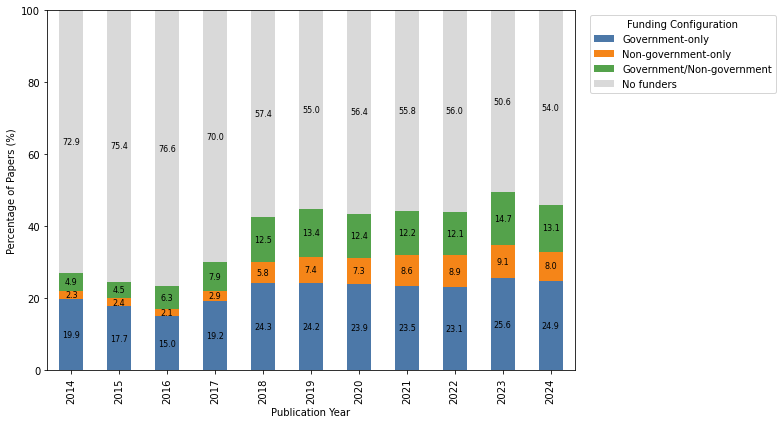

In [14]:
# =============================================================================
# Define colors for funding configurations
# =============================================================================

FUNDING_COLORS = {
    "Government-only": "#4C78A8",
    "Non-government-only": "#F58518",
    "Government/Non-government": "#54A24B",
    "No funders": "#D9D9D9"
}


# =============================================================================
# Plot annual funding proportions as a stacked bar chart
# =============================================================================

plot_df = (
    annual_proportions[
        FUNDING_CATEGORIES
    ]
    * 100
)

ax = plot_df.plot(
    kind="bar",
    stacked=True,
    figsize=(11, 6),
    color=[
        FUNDING_COLORS[category]
        for category in FUNDING_CATEGORIES
    ]
)


# =============================================================================
# Add percentage labels to each stacked segment
# =============================================================================

for container in ax.containers:
    for bar in container:

        height = bar.get_height()

        # Skip labels for zero-height segments.
        if height <= 0:
            continue

        x_position = (
            bar.get_x()
            + bar.get_width() / 2
        )

        y_position = (
            bar.get_y()
            + height / 2
        )

        ax.text(
            x_position,
            y_position,
            f"{height:.1f}",
            ha="center",
            va="center",
            fontsize=8
        )


# =============================================================================
# Format the figure
# =============================================================================

# ax.set_title(
#     "Annual Funding Configuration in LIS Publications"
# )

ax.set_xlabel(
    "Publication Year"
)

ax.set_ylabel(
    "Percentage of Papers (%)"
)

ax.set_ylim(
    0,
    100
)

ax.legend(
    title="Funding Configuration",
    bbox_to_anchor=(
        1.02,
        1
    ),
    loc="upper left"
)

plt.tight_layout()

plt.savefig(
    FIGURE_DIR
    / "LIS_annual_funding_stacked_bar.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## 10. Temporal Trends in Funding Proportions

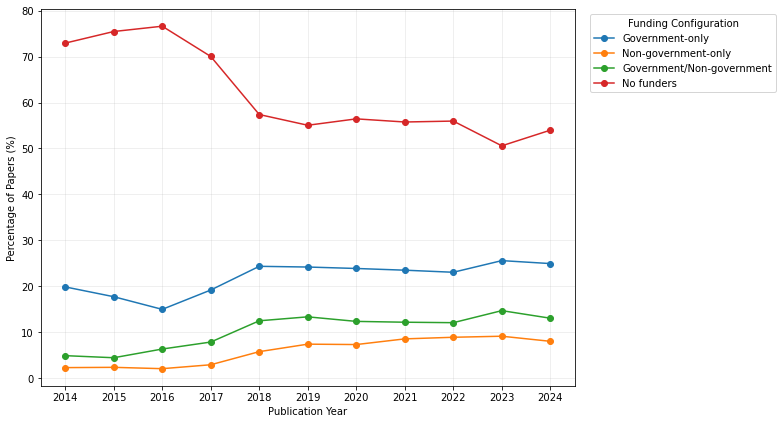

In [15]:
# =============================================================================
# Plot annual funding proportions as line plots
# =============================================================================

plot_df = (
    annual_proportions[
        FUNDING_CATEGORIES
    ]
    * 100
)

plt.figure(
    figsize=(11, 6)
)

for funding_category in FUNDING_CATEGORIES:

    plt.plot(
        plot_df.index,
        plot_df[
            funding_category
        ],
        marker="o",
        label=funding_category
    )

# plt.title(
#     "Temporal Trends in LIS Funding Configuration"
# )

plt.xlabel(
    "Publication Year"
)

plt.ylabel(
    "Percentage of Papers (%)"
)

plt.xticks(
    plot_df.index
)

plt.legend(
    title="Funding Configuration",
    bbox_to_anchor=(
        1.02,
        1
    ),
    loc="upper left"
)

plt.grid(
    alpha=0.25
)

plt.tight_layout()

plt.savefig(
    FIGURE_DIR
    / "LIS_annual_funding_line_plot.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## 11. Linear Regression Analysis of Annual Funding Trends

In [16]:
# =============================================================================
# Run one linear regression for each funding configuration
# =============================================================================

regression_results = []

years = (
    annual_proportions
    .index
    .to_numpy(
        dtype=float
    )
)

# Center the year variable so that 2014 corresponds to 0.
centered_years = (
    years
    - years.min()
)

X = sm.add_constant(
    centered_years
)

for funding_category in FUNDING_CATEGORIES:

    y = (
        annual_proportions[
            funding_category
        ]
        .to_numpy(
            dtype=float
        )
    )

    model = sm.OLS(
        y,
        X
    ).fit()

    slope = model.params[1]

    slope_ci = (
        model
        .conf_int(
            alpha=0.05
        )[1]
    )

    regression_results.append(
        {
            "Funding_Configuration":
                funding_category,

            "N_Years":
                int(
                    model.nobs
                ),

            "Slope_Proportion_Per_Year":
                float(
                    slope
                ),

            "Slope_Percentage_Points_Per_Year":
                float(
                    slope * 100
                ),

            "Slope_SE":
                float(
                    model.bse[1]
                ),

            "CI_95_Lower_Percentage_Points":
                float(
                    slope_ci[0]
                    * 100
                ),

            "CI_95_Upper_Percentage_Points":
                float(
                    slope_ci[1]
                    * 100
                ),

            "P_Value":
                float(
                    model.pvalues[1]
                ),

            "R_Squared":
                float(
                    model.rsquared
                ),

            "Adjusted_R_Squared":
                float(
                    model.rsquared_adj
                )
        }
    )

regression_results_df = pd.DataFrame(
    regression_results
)

In [17]:
def significance_marker(p_value):
    """Return conventional statistical significance markers."""

    if p_value < 0.001:
        return "***"

    if p_value < 0.01:
        return "**"

    if p_value < 0.05:
        return "*"

    return ""


regression_results_df[
    "Significance"
] = regression_results_df[
    "P_Value"
].apply(
    significance_marker
)

numeric_columns = [
    "Slope_Proportion_Per_Year",
    "Slope_Percentage_Points_Per_Year",
    "Slope_SE",
    "CI_95_Lower_Percentage_Points",
    "CI_95_Upper_Percentage_Points",
    "P_Value",
    "R_Squared",
    "Adjusted_R_Squared"
]

regression_results_df[
    numeric_columns
] = regression_results_df[
    numeric_columns
].round(4)

display(
    regression_results_df
)

,Funding_Configuration,N_Years,Slope_Proportion_Per_Year,Slope_Percentage_Points_Per_Year,Slope_SE,CI_95_Lower_Percentage_Points,CI_95_Upper_Percentage_Points,P_Value,R_Squared,Adjusted_R_Squared,Significance
0,Government-only,11,0.0081,0.8107,0.0022,0.3212,1.3001,0.0046,0.6093,0.5659,**
1,Non-government-only,11,0.0081,0.8094,0.0011,0.5572,1.0616,0.0000,0.8541,0.8379,***
2,Government/Non-government,11,0.0098,0.9767,0.0018,0.5704,1.3831,0.0004,0.7667,0.7407,***
3,No funders,11,-0.0260,-2.5968,0.0046,-3.6305,-1.5631,0.0003,0.7820,0.7578,***


In [18]:
regression_results_df.to_csv(
    TABLE_DIR
    / "LIS_linear_regression_trends.csv",
    index=False,
    encoding="utf-8-sig"
)

## 12. Annual Funding Proportions with Linear Trend Lines

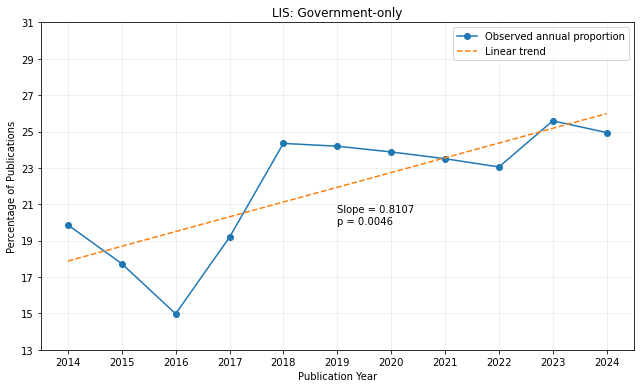

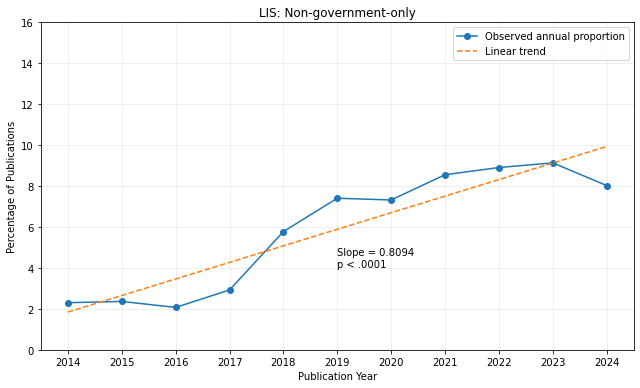

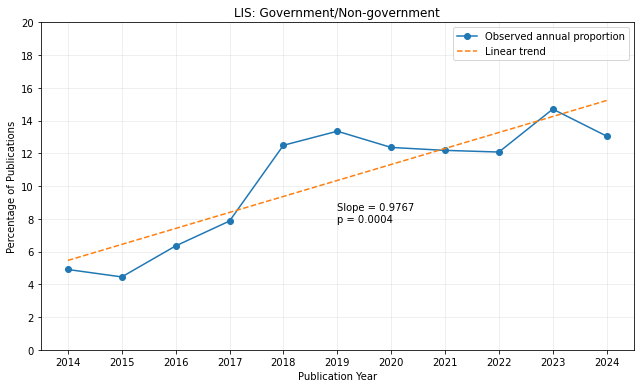

In [19]:
# =============================================================================
# Plot observed annual proportions and fitted linear trends
# for three LIS funding categories
# =============================================================================

# Exclude "No funders" from the regression plots.
PLOT_CATEGORIES = [
    "Government-only",
    "Non-government-only",
    "Government/Non-government"
]

# =============================================================================
# Customize y-axis ranges for each funding category
# =============================================================================

Y_AXIS_SETTINGS = {
    "Government-only": {
        "y_min": 13,
        "y_max": 30
    },
    "Non-government-only": {
        "y_min": 0,
        "y_max": 15
    },
    "Government/Non-government": {
        "y_min": 0,
        "y_max": 20
    }
}

# =============================================================================
# Customize annotation positions for slope and p-value
#
# x and y values are specified in data coordinates.
# Adjust these values as needed after viewing the plots.
# =============================================================================

ANNOTATION_POSITIONS = {
    "Government-only": {
        "x": 2019,
        "y": 21
    },
    "Non-government-only": {
        "x": 2019,
        "y": 5
    },
    "Government/Non-government": {
        "x": 2019,
        "y": 9
    }
}

# =============================================================================
# Prepare year variables
# =============================================================================

years = (
    annual_proportions
    .index
    .to_numpy(dtype=float)
)

centered_years = (
    years
    - years.min()
)

X = sm.add_constant(
    centered_years
)

# =============================================================================
# Store regression results and create individual figures
# =============================================================================

plot_results = {}

for funding_category in PLOT_CATEGORIES:

    proportions = (
        annual_proportions[
            funding_category
        ]
        .to_numpy(dtype=float)
        * 100
    )

    model = sm.OLS(
        proportions,
        X
    ).fit()

    fitted_values = (
        model.predict(X)
    )

    slope = model.params[1]
    p_value = model.pvalues[1]

    plot_results[funding_category] = {
        "proportions": proportions,
        "fitted_values": fitted_values,
        "slope": slope,
        "p_value": p_value
    }

    # -------------------------------------------------------------------------
    # Create an individual figure
    # -------------------------------------------------------------------------

    plt.figure(
        figsize=(9, 5.5)
    )

    plt.plot(
        years,
        proportions,
        marker="o",
        label="Observed annual proportion"
    )

    plt.plot(
        years,
        fitted_values,
        linestyle="--",
        label="Linear trend"
    )

    plt.title(
        f"LIS: {funding_category}"
    )

    plt.xlabel(
        "Publication Year"
    )

    plt.ylabel(
        "Percentage of Publications"
    )

    plt.xticks(
        years.astype(int)
    )

    # -------------------------------------------------------------------------
    # Set a category-specific y-axis range with 1-percentage-point intervals
    # -------------------------------------------------------------------------

    y_min = Y_AXIS_SETTINGS[
        funding_category
    ]["y_min"]

    y_max = Y_AXIS_SETTINGS[
        funding_category
    ]["y_max"]

    plt.ylim(
        y_min,
        y_max
    )

    plt.yticks(
        np.arange(
            y_min,
            y_max + 2,
            2
        )
    )

    # -------------------------------------------------------------------------
    # Add slope and p-value at a manually specified position
    # -------------------------------------------------------------------------

    annotation_x = ANNOTATION_POSITIONS[
        funding_category
    ]["x"]

    annotation_y = ANNOTATION_POSITIONS[
        funding_category
    ]["y"]

    if p_value < 0.0001:
        p_text = "p < .0001"
    else:
        p_text = f"p = {p_value:.4f}"

    annotation_text = (
        f"Slope = {slope:.4f} \n"
        f"{p_text}"
    )

    plt.text(
        annotation_x,
        annotation_y,
        annotation_text,
        fontsize=10,
        verticalalignment="top"
    )

    plt.legend()

    plt.grid(
        alpha=0.25
    )

    plt.tight_layout()

    safe_category_name = (
        funding_category
        .lower()
        .replace("/", "_")
        .replace(" ", "_")
    )

    plt.savefig(
        FIGURE_DIR
        / (
            f"LIS_"
            f"{safe_category_name}_"
            f"regression.png"
        ),
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

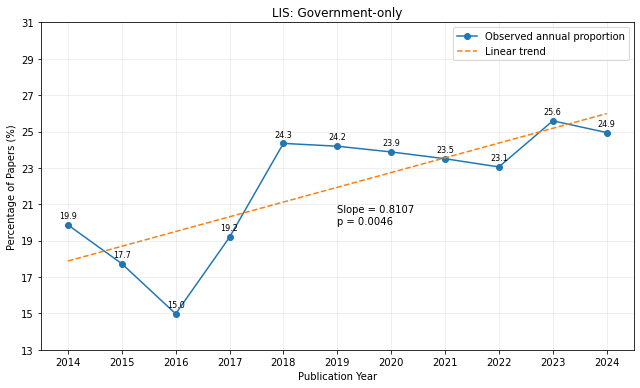

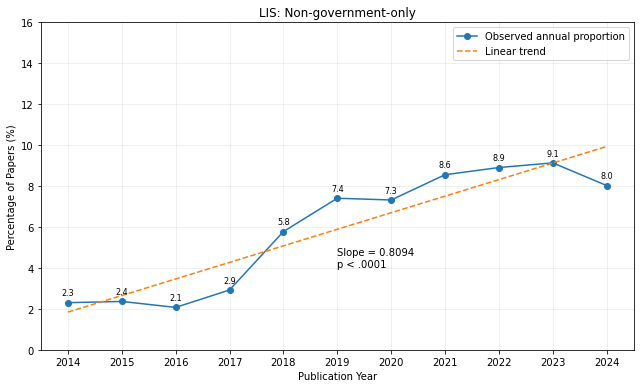

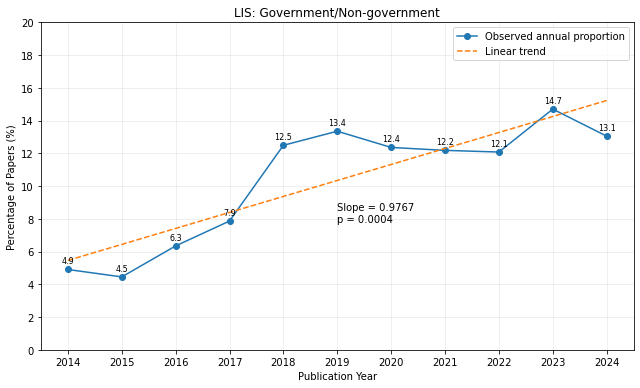

In [20]:
# =============================================================================
# Plot observed annual proportions and fitted linear trends
# for three LIS funding categories  (with observed values)
# =============================================================================

# Exclude "No funders" from the regression plots.
PLOT_CATEGORIES = [
    "Government-only",
    "Non-government-only",
    "Government/Non-government"
]

# =============================================================================
# Customize y-axis ranges for each funding category
# =============================================================================

Y_AXIS_SETTINGS = {
    "Government-only": {
        "y_min": 13,
        "y_max": 30
    },
    "Non-government-only": {
        "y_min": 0,
        "y_max": 15
    },
    "Government/Non-government": {
        "y_min": 0,
        "y_max": 20
    }
}

# =============================================================================
# Customize annotation positions for slope and p-value
#
# x and y values are specified in data coordinates.
# Adjust these values as needed after viewing the plots.
# =============================================================================

ANNOTATION_POSITIONS = {
    "Government-only": {
        "x": 2019,
        "y": 21
    },
    "Non-government-only": {
        "x": 2019,
        "y": 5
    },
    "Government/Non-government": {
        "x": 2019,
        "y": 9
    }
}

# =============================================================================
# Prepare year variables
# =============================================================================

years = (
    annual_proportions
    .index
    .to_numpy(dtype=float)
)

centered_years = (
    years
    - years.min()
)

X = sm.add_constant(
    centered_years
)

# =============================================================================
# Store regression results and create individual figures
# =============================================================================

plot_results = {}

for funding_category in PLOT_CATEGORIES:

    proportions = (
        annual_proportions[
            funding_category
        ]
        .to_numpy(dtype=float)
        * 100
    )

    model = sm.OLS(
        proportions,
        X
    ).fit()

    fitted_values = (
        model.predict(X)
    )

    slope = model.params[1]
    p_value = model.pvalues[1]

    plot_results[funding_category] = {
        "proportions": proportions,
        "fitted_values": fitted_values,
        "slope": slope,
        "p_value": p_value
    }

    # -------------------------------------------------------------------------
    # Create an individual figure
    # -------------------------------------------------------------------------

    plt.figure(
        figsize=(9, 5.5)
    )

    plt.plot(
        years,
        proportions,
        marker="o",
        label="Observed annual proportion"
    )

    # -------------------------------------------------------------------------
    # Add value labels to observed annual proportions
    # -------------------------------------------------------------------------

    for x_value, y_value in zip(
        years,
        proportions
    ):
        
        plt.text(
            x_value,
            y_value + 0.25,
            f"{y_value:.1f}",
            ha="center",
            va="bottom",
            fontsize=8
        )
    
    
    
    plt.plot(
        years,
        fitted_values,
        linestyle="--",
        label="Linear trend"
    )

    plt.title(
        f"LIS: {funding_category}"
    )

    plt.xlabel(
        "Publication Year"
    )

    plt.ylabel(
        "Percentage of Papers (%)"
    )

    plt.xticks(
        years.astype(int)
    )

    # -------------------------------------------------------------------------
    # Set a category-specific y-axis range with 1-percentage-point intervals
    # -------------------------------------------------------------------------

    y_min = Y_AXIS_SETTINGS[
        funding_category
    ]["y_min"]

    y_max = Y_AXIS_SETTINGS[
        funding_category
    ]["y_max"]

    plt.ylim(
        y_min,
        y_max
    )

    plt.yticks(
        np.arange(
            y_min,
            y_max + 2,
            2
        )
    )

    # -------------------------------------------------------------------------
    # Add slope and p-value at a manually specified position
    # -------------------------------------------------------------------------

    annotation_x = ANNOTATION_POSITIONS[
        funding_category
    ]["x"]

    annotation_y = ANNOTATION_POSITIONS[
        funding_category
    ]["y"]

    if p_value < 0.0001:
        p_text = "p < .0001"
    else:
        p_text = f"p = {p_value:.4f}"

    annotation_text = (
        f"Slope = {slope:.4f} \n"
        f"{p_text}"
    )

    plt.text(
        annotation_x,
        annotation_y,
        annotation_text,
        fontsize=10,
        verticalalignment="top"
    )

    plt.legend()

    plt.grid(
        alpha=0.25
    )

    plt.tight_layout()

    safe_category_name = (
        funding_category
        .lower()
        .replace("/", "_")
        .replace(" ", "_")
    )

    plt.savefig(
        FIGURE_DIR
        / (
            f"LIS_"
            f"{safe_category_name}_"
            f"regression.png"
        ),
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

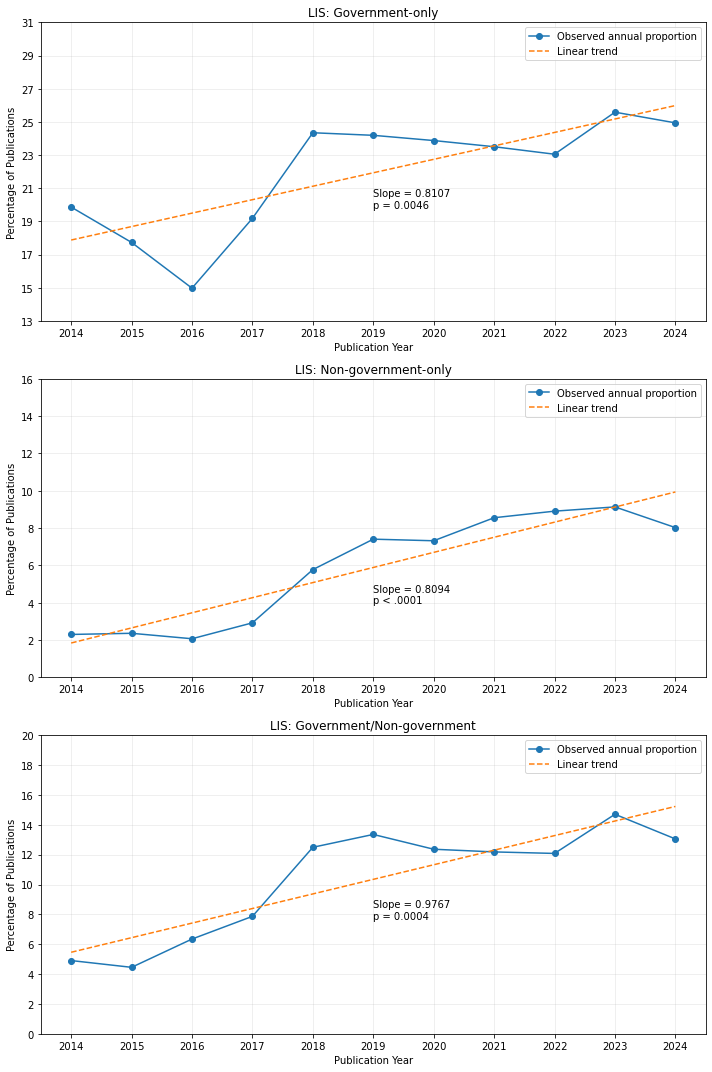

In [20]:
# =============================================================================
# Combine the three funding trend plots into one figure
# =============================================================================

fig, axes = plt.subplots(
    nrows=3,
    ncols=1,
    figsize=(10, 15)
)

for ax, funding_category in zip(
    axes,
    PLOT_CATEGORIES
):

    proportions = plot_results[
        funding_category
    ]["proportions"]

    fitted_values = plot_results[
        funding_category
    ]["fitted_values"]

    slope = plot_results[
        funding_category
    ]["slope"]

    p_value = plot_results[
        funding_category
    ]["p_value"]

    ax.plot(
        years,
        proportions,
        marker="o",
        label="Observed annual proportion"
    )

    ax.plot(
        years,
        fitted_values,
        linestyle="--",
        label="Linear trend"
    )

    ax.set_title(
        f"LIS: {funding_category}"
    )

    ax.set_xlabel(
        "Publication Year"
    )

    ax.set_ylabel(
        "Percentage of Publications"
    )

    ax.set_xticks(
        years.astype(int)
    )

    # -------------------------------------------------------------------------
    # Set category-specific y-axis range
    # -------------------------------------------------------------------------

    y_min = Y_AXIS_SETTINGS[
        funding_category
    ]["y_min"]

    y_max = Y_AXIS_SETTINGS[
        funding_category
    ]["y_max"]

    ax.set_ylim(
        y_min,
        y_max
    )

    ax.set_yticks(
        np.arange(
            y_min,
            y_max + 2,
            2
        )
    )

    # -------------------------------------------------------------------------
    # Add slope and p-value
    # -------------------------------------------------------------------------

    annotation_x = ANNOTATION_POSITIONS[
        funding_category
    ]["x"]

    annotation_y = ANNOTATION_POSITIONS[
        funding_category
    ]["y"]

    if p_value < 0.0001:
        p_text = "p < .0001"
    else:
        p_text = f"p = {p_value:.4f}"

    annotation_text = (
        f"Slope = {slope:.4f} \n"
        f"{p_text}"
    )

    ax.text(
        annotation_x,
        annotation_y,
        annotation_text,
        fontsize=10,
        verticalalignment="top"
    )

    ax.legend()

    ax.grid(
        alpha=0.25
    )

plt.tight_layout()

plt.savefig(
    FIGURE_DIR
    / "LIS_three_funding_trends_combined.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

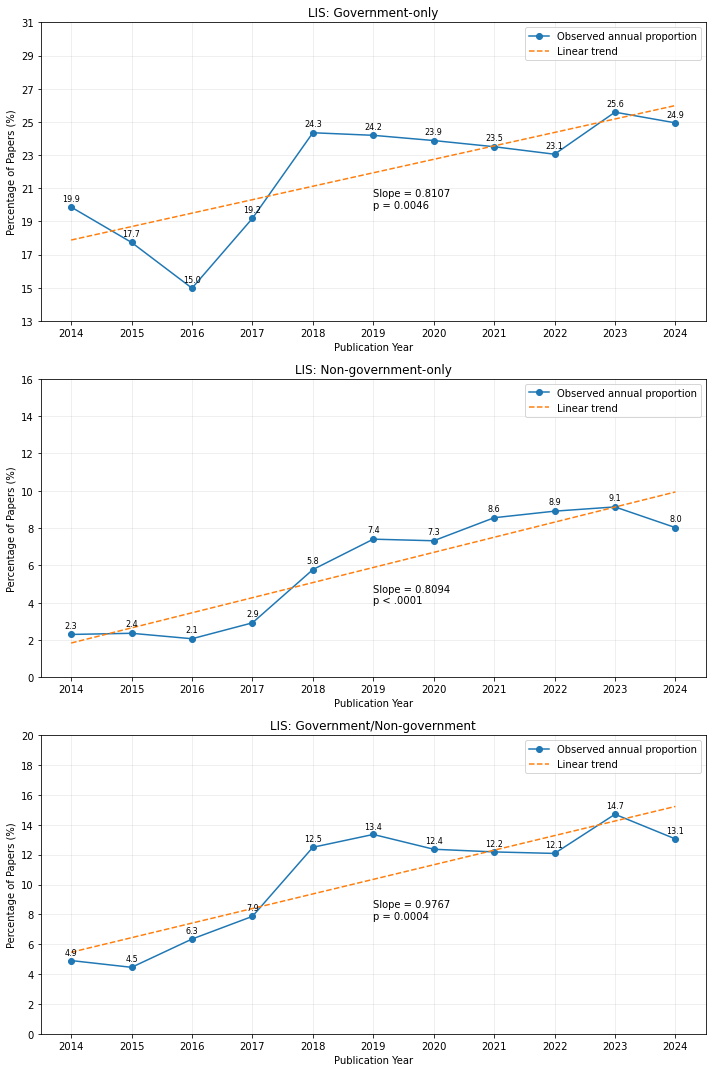

In [21]:
# =============================================================================
# Combine the three funding trend plots into one figure (with observed values)
# =============================================================================

fig, axes = plt.subplots(
    nrows=3,
    ncols=1,
    figsize=(10, 15)
)

for ax, funding_category in zip(
    axes,
    PLOT_CATEGORIES
):

    proportions = plot_results[
        funding_category
    ]["proportions"]

    fitted_values = plot_results[
        funding_category
    ]["fitted_values"]

    slope = plot_results[
        funding_category
    ]["slope"]

    p_value = plot_results[
        funding_category
    ]["p_value"]

    ax.plot(
        years,
        proportions,
        marker="o",
        label="Observed annual proportion"
    )

    # -------------------------------------------------------------------------
    # Add value labels to observed annual proportions
    # -------------------------------------------------------------------------

    for x_value, y_value in zip(
        years,
        proportions
    ):
        ax.text(
            x_value,
            y_value + 0.25,
            f"{y_value:.1f}",
            ha="center",
            va="bottom",
            fontsize=8
        )

    # -------------------------------------------------------------------------
    # Plot the fitted linear trend
    # -------------------------------------------------------------------------
    
    
    
    
    ax.plot(
        years,
        fitted_values,
        linestyle="--",
        label="Linear trend"
    )  
    
    ax.set_title(
        f"LIS: {funding_category}"
    )

    ax.set_xlabel(
        "Publication Year"
    )

    ax.set_ylabel(
        "Percentage of Papers (%)"
    )

    ax.set_xticks(
        years.astype(int)
    )

    # -------------------------------------------------------------------------
    # Set category-specific y-axis range
    # -------------------------------------------------------------------------

    y_min = Y_AXIS_SETTINGS[
        funding_category
    ]["y_min"]

    y_max = Y_AXIS_SETTINGS[
        funding_category
    ]["y_max"]

    ax.set_ylim(
        y_min,
        y_max
    )

    ax.set_yticks(
        np.arange(
            y_min,
            y_max + 2,
            2
        )
    )

    # -------------------------------------------------------------------------
    # Add slope and p-value
    # -------------------------------------------------------------------------

    annotation_x = ANNOTATION_POSITIONS[
        funding_category
    ]["x"]

    annotation_y = ANNOTATION_POSITIONS[
        funding_category
    ]["y"]

    if p_value < 0.0001:
        p_text = "p < .0001"
    else:
        p_text = f"p = {p_value:.4f}"

    annotation_text = (
        f"Slope = {slope:.4f} \n"
        f"{p_text}"
    )

    ax.text(
        annotation_x,
        annotation_y,
        annotation_text,
        fontsize=10,
        verticalalignment="top"
    )

    ax.legend()

    ax.grid(
        alpha=0.25
    )

plt.tight_layout()

plt.savefig(
    FIGURE_DIR
    / "LIS_three_funding_trends_combined.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## 13. Government-to-Non-Government Funding Involvement Ratio

In [22]:
# =============================================================================
# Calculate government and non-government sector involvement
# =============================================================================

sector_ratio = pd.DataFrame(
    index=annual_counts.index
)

sector_ratio[
    "Government_Involved_Papers"
] = (
    annual_counts[
        "Government-only"
    ]
    + annual_counts[
        "Government/Non-government"
    ]
)

sector_ratio[
    "Non_Government_Involved_Papers"
] = (
    annual_counts[
        "Non-government-only"
    ]
    + annual_counts[
        "Government/Non-government"
    ]
)

sector_ratio[
    "Government_to_Non_Government_Ratio"
] = np.where(
    sector_ratio[
        "Non_Government_Involved_Papers"
    ] > 0,

    sector_ratio[
        "Government_Involved_Papers"
    ]
    / sector_ratio[
        "Non_Government_Involved_Papers"
    ],

    np.nan
)

sector_ratio = (
    sector_ratio
    .reset_index()
)

sector_ratio[
    "Government_to_Non_Government_Ratio"
] = sector_ratio[
    "Government_to_Non_Government_Ratio"
].round(4)

display(
    sector_ratio
)

,Year,Government_Involved_Papers,Non_Government_Involved_Papers,Government_to_Non_Government_Ratio
0,2014,1313,382,3.4372
1,2015,1211,372,3.2554
2,2016,1287,508,2.5335
3,2017,1675,668,2.5075
4,2018,2430,1205,2.0166
5,2019,2570,1421,1.8086
6,2020,2955,1605,1.8411
7,2021,2824,1641,1.7209
8,2022,2978,1779,1.6740
9,2023,3546,2098,1.6902


In [23]:
sector_ratio.to_csv(
    TABLE_DIR
    / "LIS_government_non_government_ratio.csv",
    index=False,
    encoding="utf-8-sig"
)

## 14. Temporal Trend in Government-to-Non-Government Funding Ratio

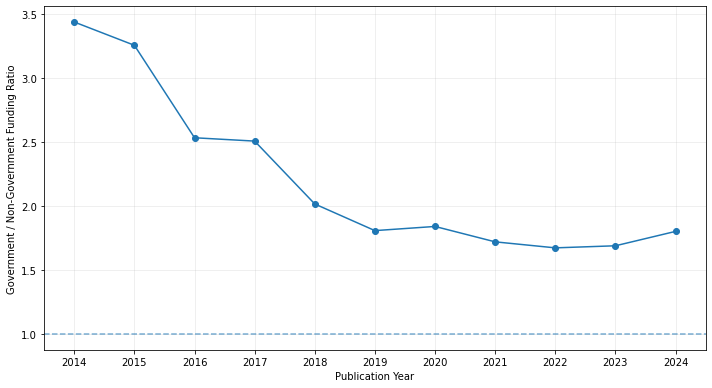

In [26]:
plt.figure(
    figsize=(10, 5.5)
)

plt.plot(
    sector_ratio[
        YEAR_COLUMN
    ],
    sector_ratio[
        "Government_to_Non_Government_Ratio"
    ],
    marker="o"
)

# A ratio of 1 indicates equal government and non-government involvement.
plt.axhline(
    y=1,
    linestyle="--",
    alpha=0.6
)

plt.xlabel(
    "Publication Year"
)

plt.ylabel(
    "Government / Non-Government Funding Ratio"
)

# plt.title(
#     "Government-to-Non-Government Funding Involvement Ratio in LIS"
# )

plt.xticks(
    sector_ratio[
        YEAR_COLUMN
    ]
)

plt.grid(
    alpha=0.25
)

plt.tight_layout()

plt.savefig(
    FIGURE_DIR
    / "LIS_government_non_government_ratio.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

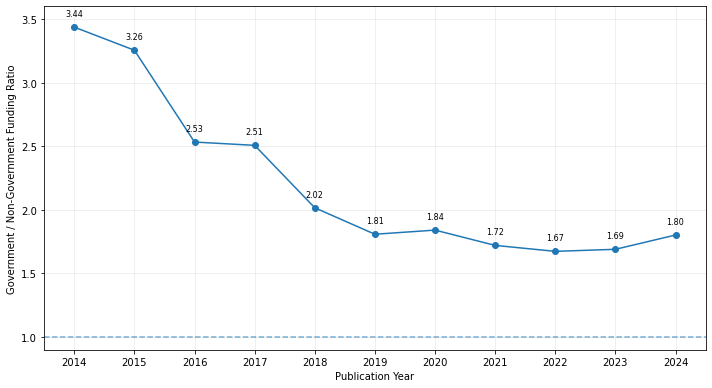

In [30]:
# =============================================================================
# Customize y-axis settings
# =============================================================================

Y_MIN = 0.9
Y_MAX = 3.6

Y_TICK_START = 1.0
Y_TICK_END = 3.5
Y_INTERVAL = 0.5

# Vertical distance between each observed point and its value label.
VALUE_LABEL_OFFSET = 0.07


# =============================================================================
# Plot the government-to-non-government funding ratio
# =============================================================================

plt.figure(
    figsize=(10, 5.5)
)

years = sector_ratio[
    YEAR_COLUMN
]

ratios = sector_ratio[
    "Government_to_Non_Government_Ratio"
]

plt.plot(
    years,
    ratios,
    marker="o"
)


# =============================================================================
# Add value labels to observed ratios
# =============================================================================

for x_value, y_value in zip(
    years,
    ratios
):
    plt.text(
        x_value,
        y_value + VALUE_LABEL_OFFSET,
        f"{y_value:.2f}",
        ha="center",
        va="bottom",
        fontsize=8
    )


# =============================================================================
# Add the reference line
# =============================================================================

# A ratio of 1 indicates equal government and non-government involvement.

plt.axhline(
    y=1,
    linestyle="--",
    alpha=0.6
)


# =============================================================================
# Customize axes
# =============================================================================

plt.xlabel(
    "Publication Year"
)

plt.ylabel(
    "Government / Non-Government Funding Ratio"
)

plt.xticks(
    years
)

plt.ylim(
    Y_MIN,
    Y_MAX
)

plt.yticks(
    np.arange(
        Y_TICK_START,
        Y_TICK_END + Y_INTERVAL,
        Y_INTERVAL
    )
)


# =============================================================================
# Format and save the figure
# =============================================================================

plt.grid(
    alpha=0.25
)

plt.tight_layout()

plt.savefig(
    FIGURE_DIR
    / "LIS_government_non_government_ratio.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## 15. Save the Publication-Level Analysis Dataset

In [31]:
lis_analysis.to_csv(
    OUTPUT_DIR
    / "LIS_publication_level_funding_analysis.csv",
    index=False,
    encoding="utf-8-sig"
)

print(
    f"All LIS analysis outputs were saved to: "
    f"{OUTPUT_DIR}"
)

All LIS analysis outputs were saved to: LIS_gov_non_gov_funding_analysis
